# Stage F — Hellinger mapping vs. linear BoVW

Resultados já calculados; **não treina modelos**. A escolha da melhor variante usa exclusivamente o AP de validação. Gera uma tabela e um gráfico para o relatório. Colocar este notebook em `results/part1/stageF/` (ou `results/stageF/`).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [
    Path('metrics.csv'),
    Path('results/part1/stageF/metrics.csv'),
    Path('results/stageF/metrics.csv'),
    Path('code/results/part1/stageF/metrics.csv'),
    Path('code/results/stageF/metrics.csv'),
]
CSV_PATH = next((p.resolve() for p in candidates if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError('metrics.csv da Stage F não encontrado')
root = CSV_PATH.parent
df = pd.read_csv(CSV_PATH)
run_path = root / 'run.json'
run_info = json.loads(run_path.read_text(encoding='utf-8')) if run_path.exists() else {}

TABLES = root / 'Tables'
IMAGES = root / 'Images'
TABLES.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

assert {'variant', 'operations', 'train_ap', 'val_ap', 'test_ap'}.issubset(df.columns)
assert df['variant'].is_unique, 'Esperado um resultado por variante'
assert df[['train_ap','val_ap','test_ap']].notna().all().all(), 'AP em falta'
assert df[['train_ap','val_ap','test_ap']].apply(lambda s: s.between(0,1)).all().all(), 'AP fora de [0,1]'
print(f'Loaded {len(df)} variants from {CSV_PATH}')


Loaded 5 variants from C:\IAVC\IAVC_proj_2\code\results\part1\stageF\metrics.csv


In [2]:
labels = {
    'linear_E': 'Linear (Stage E)',
    'e_norm_sqrt': 'Hellinger (E-L2 → √)',
    'none_sqrt': 'Hellinger (none → √)',
    'l2_sqrt': 'Hellinger (L2 → √)',
    'sqrt_l2': 'Hellinger (√ → L2)',
}
order = ['linear_E', 'e_norm_sqrt', 'none_sqrt', 'l2_sqrt', 'sqrt_l2']
raw = df.set_index('variant').loc[[v for v in order if v in set(df['variant'])]].reset_index()
if 'linear_E' not in set(raw['variant']):
    raise ValueError('Baseline linear_E não encontrado')
baseline_test = float(raw.loc[raw['variant'].eq('linear_E'), 'test_ap'].iloc[0])
selected = run_info.get('best_hellinger_variant')
if not selected:
    hellinger = raw.loc[~raw['variant'].eq('linear_E')]
    selected = str(hellinger.loc[hellinger['val_ap'].idxmax(), 'variant'])
if selected not in set(raw['variant']):
    raise ValueError(f'Variável selecionada não existe nas métricas: {selected}')

report = pd.DataFrame({
    'Variant': raw['variant'].map(labels).fillna(raw['variant']),
    'Train AP': raw['train_ap'],
    'Val AP': raw['val_ap'],
    'Test AP': raw['test_ap'],
    'Δ Test (pp)': 100*(raw['test_ap'] - baseline_test),
})
display(report.style.format({'Train AP':'{:.4f}', 'Val AP':'{:.4f}', 'Test AP':'{:.4f}', 'Δ Test (pp)':'{:+.2f}'}).hide(axis='index'))
report.to_csv(TABLES/'stageF_ap.csv', index=False)

# Exportação LaTeX: formato booktabs utilizado no relatório.
tex_map = {
    'linear_E': r'Linear (Stage E)',
    'e_norm_sqrt': r'Hellinger: E-L2 $\rightarrow\sqrt{\cdot}$',
    'none_sqrt': r'Hellinger: none $\rightarrow\sqrt{\cdot}$',
    'l2_sqrt': r'Hellinger: L2 $\rightarrow\sqrt{\cdot}$',
    'sqrt_l2': r'Hellinger: $\sqrt{\cdot}\rightarrow$ L2',
}
lines = [
    r'\begin{table}[H]',
    r'\centering',
    r'\caption{Effect of Hellinger-style feature mappings on motorbike retrieval. The selected configuration (bold) maximizes validation AP; test AP is reported only for final evaluation.}',
    r'\label{tab:stageF_ap}',
    r'\resizebox{\linewidth}{!}{%',
    r'\begin{tabular}{lrrrr}',
    r'\toprule',
    r'\textbf{Variant} & \textbf{Train AP} & \textbf{Val. AP} & \textbf{Test AP} & \textbf{$\Delta$ Test (pp)} \\',
    r'\midrule',
]
for row in raw.itertuples(index=False):
    value = (row.train_ap, row.val_ap, row.test_ap, 100*(row.test_ap-baseline_test))
    vals = [f'{value[0]:.4f}',f'{value[1]:.4f}',f'{value[2]:.4f}',f'{value[3]:+.2f}']
    name=tex_map.get(row.variant, row.variant.replace('_', r'\_'))
    if row.variant==selected:
        name=r'\textbf{' + name + '}'
        vals=[r'\textbf{' + v + '}' for v in vals]
    lines.append(name+' & '+' & '.join(vals)+r' \\')
lines += [r'\bottomrule', r'\end{tabular}%', r'}', r'\end{table}']
(TABLES/'stageF_ap.tex').write_text('\n'.join(lines)+'\n',encoding='utf-8')

print(f'Selected by validation: {selected}')
print(f'Test AP improvement vs. linear: {(float(raw.loc[raw.variant.eq(selected), "test_ap"].iloc[0])-baseline_test)*100:+.2f} pp')


Variant,Train AP,Val AP,Test AP,Δ Test (pp)
Linear (Stage E),0.9416,0.5513,0.4523,+0.00
Hellinger (E-L2 → √),1.0000,0.5380,0.4401,-1.22
Hellinger (none → √),1.0000,0.5285,0.4341,-1.83
Hellinger (L2 → √),1.0000,0.5380,0.4401,-1.22
Hellinger (√ → L2),0.9837,0.6421,0.5151,+6.27


Selected by validation: sqrt_l2
Test AP improvement vs. linear: +6.27 pp


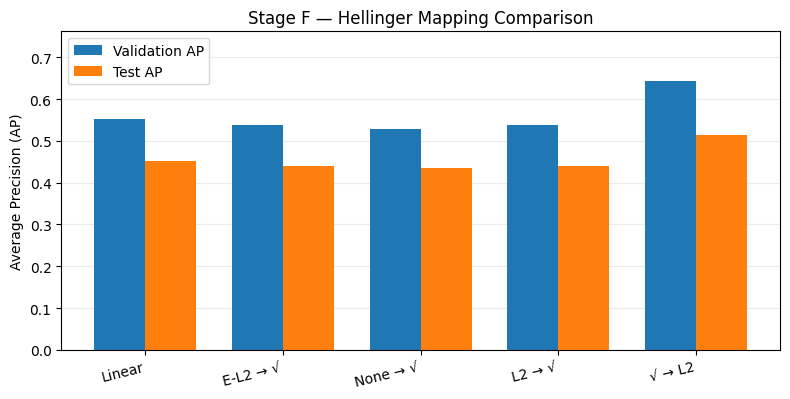

In [3]:
pos=np.arange(len(report))
w=.37
fig, ax=plt.subplots(figsize=(8,4.1))
ax.bar(pos-w/2, raw['val_ap'], width=w, label='Validation AP')
ax.bar(pos+w/2, raw['test_ap'], width=w, label='Test AP')
ax.set_xticks(pos)
ax.set_xticklabels(['Linear', 'E-L2 → √', 'None → √', 'L2 → √', '√ → L2'], rotation=14, ha='right')
ax.set_ylabel('Average Precision (AP)')
ax.set_ylim(0, min(1, float(max(raw[['val_ap','test_ap']].max()))+0.12))
ax.set_title('Stage F — Hellinger Mapping Comparison')
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES/'stageF_ap_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
